# InOx TFT campaign — the batch-1 run sheet that came back in `raw_data_received/inox/06_10_26`

After a pause of roughly a year (the last InOx measurements are from November 2025 and the February 2026 "Data Update"), the
fab team returned `sobol_constrained_batch_1_repeated (1).xlsx` together with a one-line question in `info.txt`:
*"change the substrate temperature to integer values ranging from 435 to 600 °C?"*

This notebook answers, in order:

1. **What arrived** — a run sheet (inputs only, no measurements yet): 30 conditions × 3 repetitions.
2. **Where it comes from** — it is, value for value, batch 1 of the constrained Sobol design generated by `doe/inox/doe_design.ipynb` (seed 42).
3. **Which project, which material, which inputs and outputs** — the InOx thin-film-transistor campaign.
4. **What data existed before** — iteration 0 (L8 Taguchi, September 2025), iteration 1 (replicated at ≤ 30 W, November 2025) and the
   runs 9–17 augmentation (February 2026): 17 conditions, 51 films.
5. **Why Taguchi was used first, what it showed, and why the campaign moved to a constrained Sobol design.**
6. **The design itself** — coverage, the substrate < anneal constraint, balance.
7. **The substrate-temperature question** — what "integer values 435–600 °C" changes, two ways to honour it, and what to ask back.

Nothing is written to disk unless `SAVE_OUTPUTS = True` in the setup cell; `OUT_FILES` names every item.

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import qmc
warnings.filterwarnings('ignore')
REPO_ROOT = '/data/zhq7531/IDEAL/DMREF/repository_dmref'
os.chdir(REPO_ROOT)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

RECEIVED   = 'raw_data_received/inox/06_10_26/sobol_constrained_batch_1_repeated (1).xlsx'
INFO       = 'raw_data_received/inox/06_10_26/info.txt'
ITER0      = 'raw_data_received/inox/XPS & XRD.xlsx'                                   # Sept 2025, L8, 8 conditions
ITER1      = 'raw_data_received/inox/XPS & XRD_11_06_25.xlsx'                          # Nov 2025, conditions 1-8 x 3
MASTER     = 'Processed_data_inputs/inox/second_iteration_orthogonal/XPS_XRD_with_newdata_clean_v02.xlsx'   # 17 conditions, 51 films
GP_METRICS = 'output/inox/previous_studies/previous_temp/gp_metrics.xlsx'              # April 2026 GP leave-one-experiment-out check

# ---- saving: nothing is written unless SAVE_OUTPUTS is True -------------------------------------------------
SAVE_OUTPUTS = False                                    # True -> write the items below into OUT_DIR
OUT_DIR = 'output/inox/sobol_batch1_provenance'
OUT_FILES = {                                           # file name per item; set an entry to None to skip it
    'received_summary_table':  'batch1_received_summary.xlsx',                 # §1
    'previous_data_table':     'previous_data_per_condition.xlsx',             # §4
    'mobility_fig':            'previous_data_mobility_per_condition.png',     # §4
    'ta_o2_fig':               'previous_data_ta_area_vs_o2_flow.png',         # §4
    'mobility_vs_inputs_fig':  'previous_data_mobility_vs_inputs.png',         # §4
    'promising_region_fig':    'previous_data_promising_region_map.png',       # §4
    'anova_table':             'taguchi_phase_anova.xlsx',                     # §5
    'design_correlation_fig':  'design_input_correlation_matrices.png',       # §5
    'design_pairs_fig':        'batch1_design_pairs.png',                      # §6
    'design_constraint_fig':   'batch1_design_constraint.png',                 # §6
    'revision_metrics_table':  'substrate_435_600_revision_metrics.xlsx',      # §7
    'revision_correlation_fig': 'substrate_435_600_revision_correlations.png', # §7
    'revision_A_sheet':        'batch1_revA_rounded_clamped_435_600.xlsx',     # §7 minimal edit of the received sheet
    'revision_B_sheet':        'batch1_revB_regenerated_435_600.xlsx',         # §7 regenerated design (RT kept)
    'revision_B_noRT_sheet':   'batch1_revB_regenerated_435_600_noRT.xlsx',    # §7 regenerated design (no RT runs)
}

def out_path(key, **fmt):
    # Path OUT_DIR/OUT_FILES[key] for functions that write the file themselves; None (= no file) unless SAVE_OUTPUTS.
    name = OUT_FILES.get(key)
    if not SAVE_OUTPUTS or name is None:
        return None
    os.makedirs(OUT_DIR, exist_ok=True)
    return os.path.join(OUT_DIR, name.format(**fmt))

def save(key, obj, **fmt):
    # Write obj to OUT_DIR/OUT_FILES[key]: a Figure -> .png, a DataFrame -> .xlsx, a {sheet: DataFrame} dict -> multi-sheet .xlsx.
    path = out_path(key, **fmt)
    if path is None:
        return
    if hasattr(obj, 'savefig'):
        obj.savefig(path, dpi=170, bbox_inches='tight')
    else:
        frames = obj if isinstance(obj, dict) else {'Sheet1': obj}
        with pd.ExcelWriter(path) as w:
            for sheet, d in frames.items():
                d.to_excel(w, sheet_name=sheet, index=not isinstance(d.index, pd.RangeIndex))
    print('saved', path)

P = dict(blue='#2a78d6', orange='#eb6834', green='#1baf7a', muted='#898781', grid='#e1e0d9', axis='#c3c2b7',
         ink='#0b0b0b', ink2='#52514e', surface='#fcfcfb', window='#f0efec')
plt.rcParams.update({'figure.facecolor': P['surface'], 'axes.facecolor': P['surface'], 'axes.edgecolor': P['axis'],
                     'axes.grid': True, 'grid.color': P['grid'], 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'text.color': P['ink'], 'axes.labelcolor': P['ink2'],
                     'xtick.color': P['ink2'], 'ytick.color': P['ink2'], 'xtick.labelsize': 8, 'ytick.labelsize': 8,
                     'axes.labelsize': 9, 'axes.titlesize': 9, 'legend.frameon': False, 'legend.fontsize': 8})
print('SAVE_OUTPUTS =', SAVE_OUTPUTS, '| nothing is written to', OUT_DIR, 'unless set to True')

SAVE_OUTPUTS = False | nothing is written to output/inox/sobol_batch1_provenance unless set to True


## 1. What arrived

One workbook and a one-line note. The workbook has the six process factors and no measurement columns, so it is a **run
sheet** (conditions to fabricate), not data.

In [2]:
rec = pd.read_excel(RECEIVED)
print('info.txt:', open(INFO).read().strip())
FACTORS = ['Power (W)', 'Substrate Temperature (C)', 'Oxygen Flow Rate (sccm)', 'Background Pressure (Torr)',
           'Annealing Temperature (C)', 'Annealing Condition']
NUM = FACTORS[:-1]
u = rec.drop_duplicates('Sample').set_index('Sample')
reps = rec.groupby('Sample').size()
print(f'\n{len(rec)} rows = {len(u)} conditions x {sorted(reps.unique().tolist())} repetitions; columns: {list(rec.columns)}')
decimals = lambda col: int(max((len(str(v).split('.')[1]) if '.' in str(v) and not str(v).endswith('.0') else 0) for v in col))
summary = pd.DataFrame({'min': u[NUM].min(), 'max': u[NUM].max(), 'distinct values': u[NUM].nunique(),
                        'decimals in the sheet': [decimals(u[c]) for c in NUM]})
display(summary)
rt = int((u['Substrate Temperature (C)'] == 25).sum())
print('annealing condition:', u['Annealing Condition'].value_counts().to_dict(),
      f'| room-temperature (25 C) depositions: {rt} of {len(u)} | heated substrates: {len(u) - rt}, '
      f'{u.loc[u["Substrate Temperature (C)"] > 25, "Substrate Temperature (C)"].min():.1f}-{u["Substrate Temperature (C)"].max():.1f} C')
print('constraint substrate < anneal holds for every condition:', bool((u['Substrate Temperature (C)'] < u['Annealing Temperature (C)']).all()))
display(rec.head(9))
save('received_summary_table', {'received': rec, 'summary': summary.rename_axis('factor').reset_index()})

info.txt: change the substrate temperature to integer values ranging from 435
  to 600 °C?

90 rows = 30 conditions x [3] repetitions; columns: ['Sample', 'Repetition', 'Power (W)', 'Substrate Temperature (C)', 'Oxygen Flow Rate (sccm)', 'Background Pressure (Torr)', 'Annealing Temperature (C)', 'Annealing Condition']


,min,max,distinct values,decimals in the sheet
Power (W),10.0,30.0,20,0
Substrate Temperature (C),25.0,597.2,27,1
Oxygen Flow Rate (sccm),0.3,2.9,25,1
Background Pressure (Torr),2.1,4.0,19,1
Annealing Temperature (C),196.0,600.0,26,0


annealing condition: {'O': 15, 'N': 15} | room-temperature (25 C) depositions: 4 of 30 | heated substrates: 26, 407.7-597.2 C
constraint substrate < anneal holds for every condition: True


,Sample,Repetition,Power (W),Substrate Temperature (C),Oxygen Flow Rate (sccm),Background Pressure (Torr),Annealing Temperature (C),Annealing Condition
0,1,1,19,556.8,2.5,2.1,570,O
1,1,2,19,556.8,2.5,2.1,570,O
2,1,3,19,556.8,2.5,2.1,570,O
3,2,1,28,407.7,1.0,3.4,579,N
4,2,2,28,407.7,1.0,3.4,579,N
5,2,3,28,407.7,1.0,3.4,579,N
6,3,1,20,490.4,2.2,2.8,563,N
7,3,2,20,490.4,2.2,2.8,563,N
8,3,3,20,490.4,2.2,2.8,563,N


**Reading it.** Thirty conditions, each listed three times (Repetition 1–3), six factors. Power is an integer, the oxygen
flow and pressure have one decimal, the annealing temperature is an integer, and the substrate temperature has one decimal
except for four room-temperature runs at 25 °C. Two details to carry forward: the pressure column is labelled "Torr" but
the values 2.1–4.0 are **mTorr** (the generator's bounds are 2–4 mTorr; the label slip is inherited from the generator, see
§2), and the annealing condition is coded `O` / `N` for O₂ / N₂.

## 2. Where it comes from

`doe/inox/doe_design.ipynb` (section *"Sobol w constrained substrate 0 or 400 and above"*) generates batches of a
scrambled Sobol sequence in six dimensions and maps them onto the factor ranges with two special rules: the substrate
temperature is **either room temperature (25 °C, with probability 0.14) or uniform in 400–600 °C**, and the annealing
temperature is drawn **above the substrate temperature** (lower bound max(150 °C, T_sub)) up to 600 °C. Batch 1 uses seed 42,
30 samples, 3 repetitions. The function below is a faithful copy of that generator with the substrate range and its rounding
exposed as arguments (defaults = the original), so the received file can be regenerated and compared value for value.

In [3]:
def generate_batch(batch_number=1, n_samples=30, seed=42, d=6, prob_room_temp=0.14,
                   substrate_bounds=(400.0, 600.0), integer_substrate=False,
                   power_bounds=(10.0, 30.0), oxygen_bounds=(0.3, 3.0), pressure_bounds=(2.0, 4.0), anneal_bounds=(150.0, 600.0)):
    # Copy of generate_batch() in doe/inox/doe_design.ipynb; only the substrate range / rounding were made arguments.
    sampler = qmc.Sobol(d=d, scramble=True, seed=seed)
    if batch_number > 1:
        sampler.fast_forward((batch_number - 1) * n_samples)
    U = sampler.random(n=n_samples)
    power = np.round(qmc.scale(U[:, [0]], [power_bounds[0]], [power_bounds[1]]).flatten()).astype(int)
    oxygen = qmc.scale(U[:, [2]], [oxygen_bounds[0]], [oxygen_bounds[1]]).flatten()
    pressure = qmc.scale(U[:, [3]], [pressure_bounds[0]], [pressure_bounds[1]]).flatten()
    u_sub, u_ann, u_cond = U[:, 1], U[:, 4], U[:, 5]
    anneal_cond = np.where(u_cond < 0.5, 'N', 'O')
    substrate = np.zeros(n_samples); anneal = np.zeros(n_samples, dtype=int); eps = 1e-6
    lo, hi = substrate_bounds
    for i in range(n_samples):
        if u_sub[i] < prob_room_temp:
            s = 25.0
        else:
            s = lo + ((u_sub[i] - prob_room_temp) / (1.0 - prob_room_temp)) * (hi - lo)
            if integer_substrate:
                s = float(int(np.round(s)))
        substrate[i] = s
        lower_ann, upper_ann = max(anneal_bounds[0], s + eps), anneal_bounds[1]
        if lower_ann >= upper_ann:
            s = anneal_bounds[1] - 2.0; substrate[i] = s; lower_ann = s + eps
        ann_val = int(np.round(lower_ann + u_ann[i] * (upper_ann - lower_ann)))
        if ann_val <= s:
            ann_val = int(np.floor(s)) + 1
        if ann_val > int(anneal_bounds[1]):
            ann_val = int(anneal_bounds[1])
            if ann_val <= s:
                s = float(ann_val - 1); substrate[i] = s
        anneal[i] = ann_val
    return pd.DataFrame({'Sample': np.arange(1, n_samples + 1) + (batch_number - 1) * n_samples,
                         'Power (W)': power, 'Substrate Temperature (C)': np.round(substrate, 1),
                         'Oxygen Flow Rate (sccm)': np.round(oxygen, 1), 'Background Pressure (Torr)': np.round(pressure, 1),
                         'Annealing Temperature (C)': anneal, 'Annealing Condition': anneal_cond})

def repeated(df, n_repeats=3):
    df = df.drop(columns=[c for c in ['Repetition', 'Batch'] if c in df.columns])
    out = df.loc[df.index.repeat(n_repeats)].reset_index(drop=True)
    out.insert(1, 'Repetition', out.groupby('Sample').cumcount() + 1)
    return out

regen = repeated(generate_batch())
cols = list(rec.columns)
identical = regen[cols].equals(rec[cols])
print('regenerated (seed 42, n = 30, prob_room_temp = 0.14, substrate 400-600 C, 3 repetitions) == received file:', identical)
assert identical, 'the received sheet is not the seed-42 batch 1'

regenerated (seed 42, n = 30, prob_room_temp = 0.14, substrate 400-600 C, 3 repetitions) == received file: True


**Verdict.** The received workbook is exactly the seed-42 batch 1 of the constrained Sobol generator (only the generator's
`Batch` column was dropped). So the fab team is sending back **our own design** for confirmation before fabricating it,
together with a request to change how the substrate temperature is specified (§7). The DoE notebook also documents the
designs that preceded this one — the L32 Taguchi array containing the fabricated L8, the first Sobol drafts, and the
constrained version `v03` — which is the thread picked up in §5.

## 3. The project, the material, the inputs and the outputs

**Project.** The first DMREF campaign in this repository: sputtered **indium-oxide (InOx) thin-film-transistor channels**,
fabricated and characterised by the collaborating fab team (their slides call it the "NW collaboration work", goal
*"optimize In₂O₃ growth"*), with the design of experiments and the modelling done here. The design files are named
`L32_design_inOX_BEOL`, i.e. the process is meant to stay compatible with a back-end-of-line thermal budget, which is why
the first anneal levels were 150 and 400 °C.

**Material.** Reactively sputtered indium oxide. XPS tracks In 3d, O 1s **and Ta 4f**: tantalum is present in the films
(the fab team's February 2026 note speaks of the Ta₂O₅ deposition rate changing with O₂ flow), so the channel is a
Ta-containing indium oxide. The exact target / co-sputtering arrangement is not recorded in the repository — worth asking
the fab team to write it down for the resumed campaign.

**Inputs (6 process knobs).**

| Factor | Taguchi phase (iterations 0–1, runs 9–17) | Constrained-Sobol batch 1 (this sheet) |
|---|---|---|
| Power (W) | 10, 30 (50 in iteration 0: films insulating, targets damaged) · 20 added in runs 9–17 | 10 – 30, integer |
| Substrate temperature (°C) | RT (25), 400 | 25 (4 of 30 runs) or 400 – 600, one decimal |
| O₂ flow (sccm) | 0.3, 3.0 · 2.0 added in runs 9–17 | 0.3 – 3.0, one decimal |
| Background pressure (mTorr) | 2, 4 | 2 – 4, one decimal (header says "Torr") |
| Anneal condition | O₂, N₂ | O / N, 15 : 15 |
| Anneal temperature (°C) | 150, 400 (600 considered for the mixed-level design) | 150 – 600, integer, **always above the substrate temperature** |

**Outputs (characterisation).**

| Output | Columns in the data files | Role |
|---|---|---|
| Hall mobility (cm²/V·s) | `Hall Mobility (cm^2/V·s)` | the objective (maximise); "insulating" when no Hall signal |
| XPS | `In3d_p1/p2`, `O1s_p1`, `Ta4f_p1/p2` (binding energies), `Area_In3d`, `Area_O1s`, `Area_Ta4f` | composition / chemical state; Ta area "too weak" → 0 in the master table |
| XRD | `Peak01–03` (2θ), `Height01–03`, `FWHM01–03` | crystallinity; the fab team saw phase separation in iteration 0 and asked whether crystalline orientation should become an output |

## 4. What came before — the data behind the Taguchi phase

| When | What happened | Where it is |
|---|---|---|
| 15–17 Sept 2025 | **Iteration 0**: L8 Taguchi, 8 conditions (power 10 / 50 W), XPS + XRD + Hall. Films 6–8 insulating. Fab slide: *"tried some extreme conditions but the samples are all insulating and our targets are damaged … parameter ranges were reduced"*; *"since multiple parameters change in each experiment, it's hard to isolate which factor affects Hall mobility; the dataset is too small"*. | `raw_data_received/inox/data_09_17_25/` (update.pptx, xps.zip, xrd.zip), `raw_data_received/inox/XPS & XRD.xlsx` |
| 5–6 Nov 2025 | **Iteration 1**: conditions 1–8 re-made with 3 samples each at ≤ 30 W (a first replicate set had turned insulating after a month in storage while the Hall tool was down). *"Except for conditions 1 and 2, other conditions exhibit good repeatability."* | `raw_data_received/inox/data_11_05_25/`, `raw_data_received/inox/XPS & XRD_11_06_25.xlsx` |
| 6 Feb 2026 | **"Data Update"**: conditions 9–17 (× 3) with XRD / XPS tables; the oxygen-sweep augmentation (20 W, 2.0 sccm levels). Fab note: *O₂ flow strongly affects the deposition rate, especially for Ta₂O₅ — the Ta 4f area decreases as O₂ flow increases; can the model check this trend?* Also: the tool allows O₂ flow below the 0.3 sccm minimum used so far. | `raw_data_received/inox/condition09_17/` |
| Apr – May 2026 | NU side: data pipeline → 51-row master table; analysis notebook (OLS / ANOVA / GP / BO / LVGP / trees); DoE notebook (L32 containing the L8, mixed-level Taguchi, Sobol, constrained Sobol v03 → **this batch-1 sheet**). | `data_pipeline/inox/`, `analysis/inox/analysis.ipynb`, `doe/inox/doe_design.ipynb` |
| May – Oct 2026 | InOx paused; the PdO campaign ran (`pdo/` folders, `PROJECT_STATUS.md`). | — |
| 8 Oct 2026 | Batch-1 sheet returned with the 435–600 °C question. | `raw_data_received/inox/06_10_26/` |

The next cell loads iteration 0 and the 51-row master and summarises every condition that was fabricated.

17 conditions, 51 films, 47 with a Hall mobility (4 missing: insulating / not measured)


,Power (W),Substrate Temp (°C),O2 Flow (sccm),Pressure (mTorr),Anneal Condition,Anneal Temp (°C),n_films,n_hall,mobility_mean,mobility_sd,CV_%,iteration0 (Sept 2025; exp 5-8 were at 50 W)
Experiment,,,,,,,,,,,,
1,10,25,0.3,2,O2,150,3,3,18.83,12.50,66.40,6.58
2,10,25,0.3,4,N2,400,3,3,27.37,11.61,42.43,2.46
3,10,400,3.0,2,O2,400,3,3,60.00,1.80,3.00,55.8
4,10,400,3.0,4,N2,150,3,3,27.00,3.04,11.26,42.9
5,30,25,3.0,4,O2,400,3,3,6.63,1.22,18.47,16.4
6,30,25,3.0,2,N2,150,3,3,10.17,4.59,45.19,insulating
7,30,400,0.3,2,N2,400,3,3,10.81,3.02,27.96,insulating
8,30,400,0.3,4,O2,150,3,3,9.88,2.31,23.42,insulating
9,20,25,3.0,4,N2,400,3,3,55.47,6.49,11.71,NaN


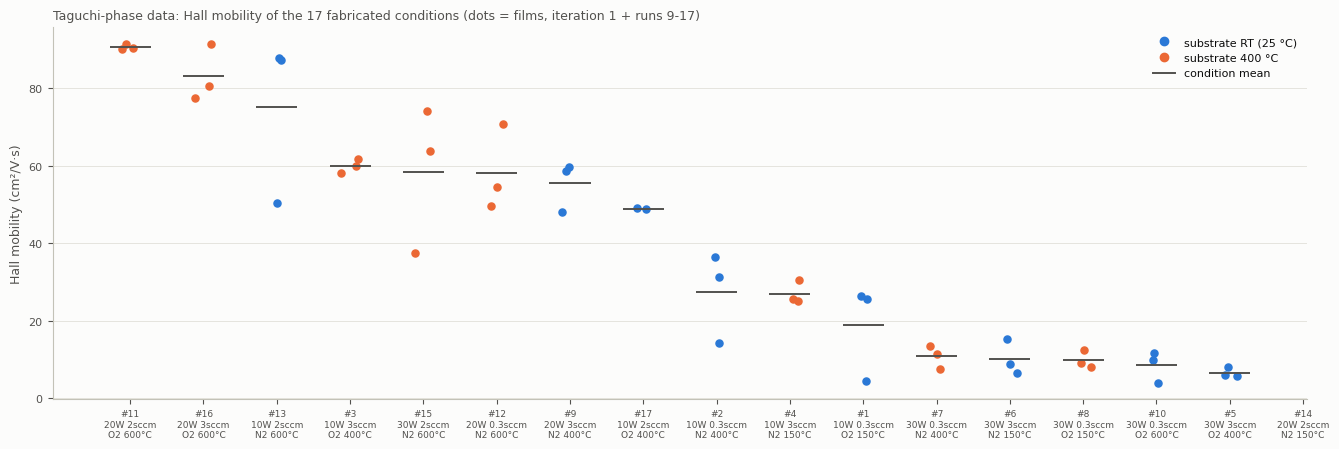

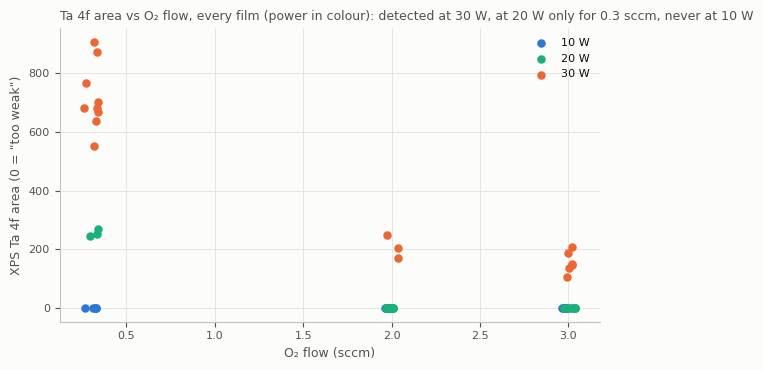

In [4]:
HALL = 'Hall Mobility (cm^2/V·s)'
FAC = ['Power (W)', 'Substrate Temp (°C)', 'O2 Flow (sccm)', 'Pressure (mTorr)', 'Anneal Condition', 'Anneal Temp (°C)']
master = pd.read_excel(MASTER, sheet_name='master_xps_xrd')
master = master.loc[:, ~master.columns.str.contains(r'\.\d$')]          # drop duplicated merge keys
it0 = pd.read_excel(ITER0, sheet_name='Experiments').set_index('Experiments')

cond = master.groupby('Experiment').agg(**{f: (f, 'first') for f in FAC}, n_films=('Trial', 'size'), n_hall=(HALL, 'count'),
                                        mobility_mean=(HALL, 'mean'), mobility_sd=(HALL, 'std'))
cond['CV_%'] = 100 * cond.mobility_sd / cond.mobility_mean
cond['iteration0 (Sept 2025; exp 5-8 were at 50 W)'] = it0['Hall_mobility_cm2_per_Vs'].reindex(cond.index)
print(f'{master.Experiment.nunique()} conditions, {len(master)} films, {master[HALL].notna().sum()} with a Hall mobility '
      f'({master[HALL].isna().sum()} missing: insulating / not measured)')
display(cond.round(2))
save('previous_data_table', {'per_condition': cond.reset_index(), 'master_51_films': master})

# --- figure: mobility per condition, replicate films + condition mean, coloured by substrate temperature
order = cond.sort_values('mobility_mean', ascending=False).index.tolist()
colour = {25: P['blue'], 400: P['orange']}
fig, ax = plt.subplots(figsize=(13.5, 4.6))
rng = np.random.default_rng(0)
for k, e in enumerate(order):
    films = master.loc[master.Experiment == e, HALL].dropna()
    c = colour[int(cond.loc[e, 'Substrate Temp (°C)'])]
    ax.scatter(k + rng.uniform(-0.12, 0.12, len(films)), films, s=26, color=c, zorder=3)
    ax.hlines(cond.loc[e, 'mobility_mean'], k - 0.28, k + 0.28, color=P['ink2'], lw=1.4, zorder=4)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"#{e}\n{int(cond.loc[e, 'Power (W)'])}W {cond.loc[e, 'O2 Flow (sccm)']:g}sccm\n{cond.loc[e, 'Anneal Condition']} {int(cond.loc[e, 'Anneal Temp (°C)'])}°C"
                    for e in order], fontsize=6.5)
ax.set_ylabel('Hall mobility (cm²/V·s)'); ax.grid(axis='x', visible=False)
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=P['blue'], label='substrate RT (25 °C)'),
                   Line2D([], [], marker='o', ls='', color=P['orange'], label='substrate 400 °C'),
                   Line2D([], [], color=P['ink2'], lw=1.4, label='condition mean')], loc='upper right')
ax.set_title('Taguchi-phase data: Hall mobility of the 17 fabricated conditions (dots = films, iteration 1 + runs 9-17)', loc='left', color=P['ink2'])
fig.tight_layout(); save('mobility_fig', fig); plt.show()

# --- the fab team's question: does the Ta 4f area fall with O2 flow?
fig, ax = plt.subplots(figsize=(6.2, 3.8))
pw_colour = {10: P['blue'], 20: P['green'], 30: P['orange']}
for pw, c in pw_colour.items():
    s = master[master['Power (W)'] == pw]
    ax.scatter(s['O2 Flow (sccm)'] + rng.uniform(-0.04, 0.04, len(s)), s['Area_Ta4f'], s=26, color=c, label=f'{pw} W', zorder=3)
ax.set_xlabel('O₂ flow (sccm)'); ax.set_ylabel('XPS Ta 4f area (0 = "too weak")')
ax.set_title('Ta 4f area vs O₂ flow, every film (power in colour): detected at 30 W, at 20 W only for 0.3 sccm, never at 10 W', loc='left', color=P['ink2'])
ax.legend(loc='upper right'); fig.tight_layout(); save('ta_o2_fig', fig); plt.show()

**Reading the previous data.** Seventeen conditions, 51 films, 47 with a Hall value (condition 14 — 20 W, room temperature,
N₂ 150 °C — has none; condition 17 has two). The ranking is dominated by the **600 °C anneal** that the runs 9–17 augmentation
introduced: condition 11 (20 W, 400 °C substrate, 2.0 sccm, 4 mTorr, O₂ 600 °C) reaches 90.7 ± 0.6 cm²/V·s, condition 16
(20 W, 400 °C, 3.0 sccm, O₂ 600 °C) 83 ± 7 and condition 13 (10 W, room temperature, 2.0 sccm, N₂ 600 °C) 75 ± 21, whereas
the best of the original L8, condition 3 (10 W, 400 °C, 3.0 sccm, O₂ 400 °C), is 60 ± 2 with the tightest replicates. At
150 or 400 °C anneal every 30 W film sits at or below ≈ 11 cm²/V·s (conditions 5–8); only the 600 °C anneal lifts a 30 W
film (condition 15, 58 ± 19). The room-temperature 10 W films (conditions 1 and 2) are the noisiest (CV 42–66 %), and
iteration 0 had shown that 50 W makes the films insulating. The directions are consistent — hotter anneal, lower power,
2–3 sccm rather than 0.3 sccm, heated substrate — and they are the reason the next design extends the anneal to 600 °C and
the substrate to 400–600 °C.

On the fab team's Ta question: at fixed power the Ta 4f area falls steeply with O₂ flow — 30 W: 550–905 at 0.3 sccm,
170–250 at 2.0 sccm, 110–210 at 3.0 sccm; 20 W: ≈ 250 at 0.3 sccm and below detection at 2.0 / 3.0 sccm; 10 W: never
detected. So their observation holds within each power level, and power matters at least as much; a continuous design is
what will separate the two cleanly.

**Where the promising region is.** Every strong effect points the same way, so the good films sit in one corner of the
Taguchi grid: **power 10–20 W, substrate 400 °C, O₂ flow 2–3 sccm, anneal 600 °C** (pressure and anneal gas do not
matter). The first figure shows mobility against each of the four significant inputs with the other strong factor in
colour; the second maps the mean mobility of every (power, anneal temperature) cell that was fabricated, split by substrate
level, and overlays the 30 batch-1 conditions to show what the new design will sample in and around that corner. Cells
marked "not run" are combinations the two-level designs never visited — the gaps a space-filling design is meant to close.

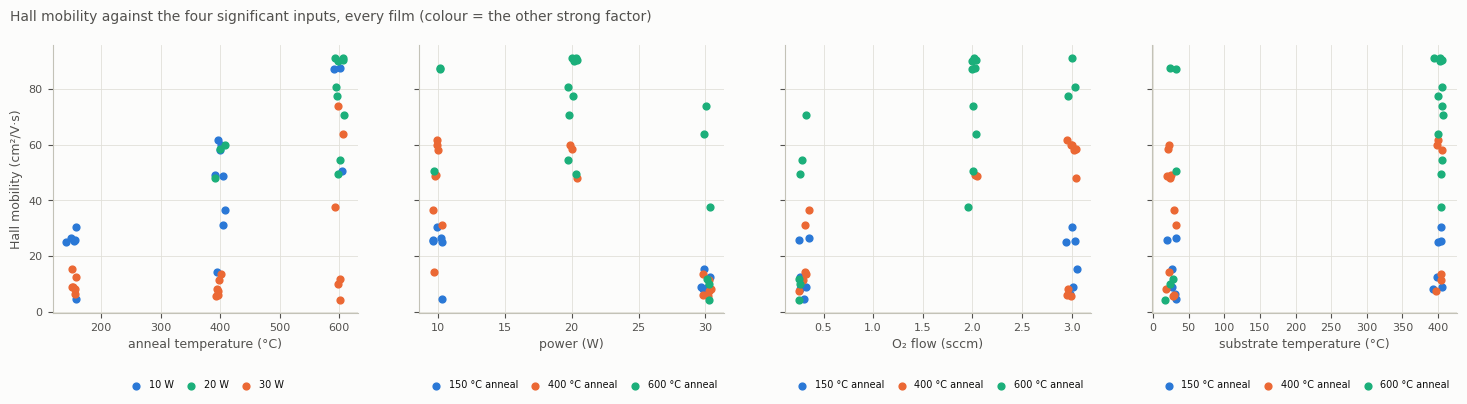

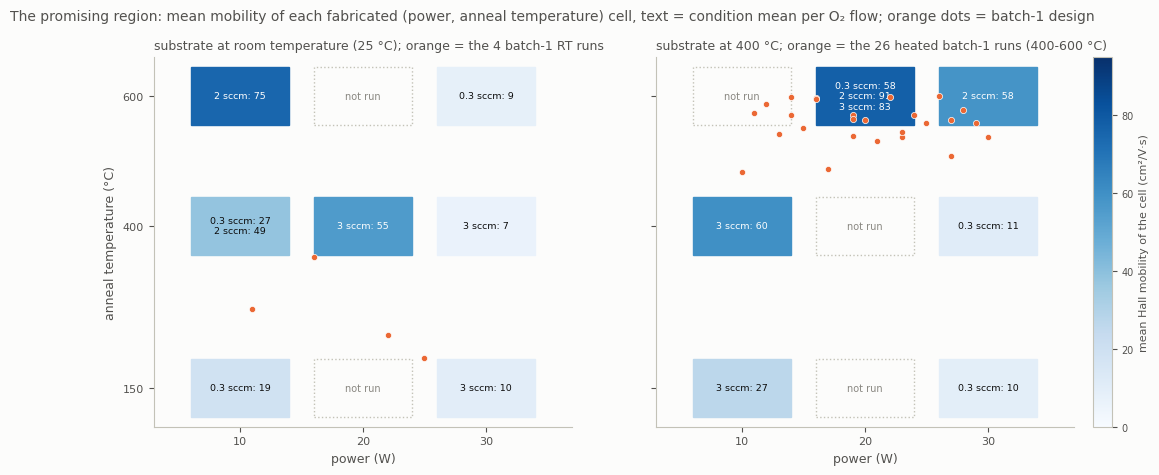

In [5]:
ANN_COL = {150: P['blue'], 400: P['orange'], 600: P['green']}     # fixed colour per anneal level
PW_COL = {10: P['blue'], 20: P['green'], 30: P['orange']}         # fixed colour per power level
m_ok = master.dropna(subset=[HALL])

# --- Figure A: mobility against each significant input, every film
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
panels = [('Anneal Temp (°C)', 'anneal temperature (°C)', 'Power (W)', PW_COL, 'W', 'upper left'),
          ('Power (W)', 'power (W)', 'Anneal Temp (°C)', ANN_COL, '°C anneal', 'upper right'),
          ('O2 Flow (sccm)', 'O₂ flow (sccm)', 'Anneal Temp (°C)', ANN_COL, '°C anneal', 'upper left'),
          ('Substrate Temp (°C)', 'substrate temperature (°C)', 'Anneal Temp (°C)', ANN_COL, '°C anneal', 'upper left')]
for ax, (x, xlabel, hue, cmap, unit, loc) in zip(axes, panels):
    span = m_ok[x].max() - m_ok[x].min()
    for lvl, c in cmap.items():
        sel = m_ok[m_ok[hue] == lvl]
        ax.scatter(sel[x] + rng.uniform(-0.02, 0.02, len(sel)) * span, sel[HALL], s=24, color=c, label=f'{lvl} {unit}', zorder=3)
    ax.set_xlabel(xlabel); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=7, handletextpad=0.3, columnspacing=0.8)
axes[0].set_ylabel('Hall mobility (cm²/V·s)')
fig.suptitle('Hall mobility against the four significant inputs, every film (colour = the other strong factor)', x=0.01, ha='left', fontsize=10, color=P['ink2'])
fig.tight_layout(); save('mobility_vs_inputs_fig', fig); plt.show()

# --- Figure B: the promising region as a map of mean mobility per (power, anneal) cell, one panel per substrate level,
#     cell text = condition mean per O2 flow, batch-1 design points overlaid
from matplotlib.colors import Normalize
from matplotlib import cm
cond_means = m_ok.groupby(['Substrate Temp (°C)', 'Power (W)', 'Anneal Temp (°C)', 'O2 Flow (sccm)'])[HALL].mean()
pw_levels, ann_levels = [10, 20, 30], [150, 400, 600]
norm = Normalize(0, 95); cmap_seq = plt.get_cmap('Blues')
sub_col, ann_col = 'Substrate Temperature (C)', 'Annealing Temperature (C)'
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
for ax, (lvl, title, dpts) in zip(axes, [(25, 'substrate at room temperature (25 °C); orange = the 4 batch-1 RT runs', u[u[sub_col] == 25]),
                                         (400, 'substrate at 400 °C; orange = the 26 heated batch-1 runs (400-600 °C)', u[u[sub_col] > 25])]):
    for pw in pw_levels:
        for an in ann_levels:
            try:
                cell = cond_means.loc[(lvl, pw, an)]
            except KeyError:
                cell = None
            if cell is not None and len(cell):
                mean = float(cell.mean())
                ax.add_patch(plt.Rectangle((pw - 4, an - 45), 8, 90, color=cmap_seq(norm(mean)), zorder=2))
                txt = '\n'.join(f'{o2:g} sccm: {v:.0f}' for o2, v in cell.sort_index().items())
                ax.text(pw, an, txt, ha='center', va='center', fontsize=6.8, color='white' if mean > 55 else P['ink'], zorder=4)
            else:
                ax.add_patch(plt.Rectangle((pw - 4, an - 45), 8, 90, fill=False, edgecolor=P['axis'], ls=':', zorder=2))
                ax.text(pw, an, 'not run', ha='center', va='center', fontsize=7, color=P['muted'], zorder=4)
    ax.scatter(dpts['Power (W)'], dpts[ann_col], s=20, color=P['orange'], edgecolor='white', linewidth=0.5, zorder=5)
    ax.set_xlim(3, 37); ax.set_ylim(90, 660); ax.set_xticks(pw_levels); ax.set_yticks(ann_levels); ax.grid(False)
    ax.set_xlabel('power (W)'); ax.set_title(title, loc='left', fontsize=9, color=P['ink2'])
axes[0].set_ylabel('anneal temperature (°C)')
cb = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap_seq), ax=axes.tolist(), fraction=0.03, pad=0.02)
cb.set_label('mean Hall mobility of the cell (cm²/V·s)', fontsize=8); cb.ax.tick_params(labelsize=7)
fig.suptitle('The promising region: mean mobility of each fabricated (power, anneal temperature) cell, text = condition mean per O₂ flow; '
             'orange dots = batch-1 design', x=0.01, ha='left', fontsize=10, color=P['ink2'])
save('promising_region_fig', fig); plt.show()

**Reading the map.** The top of every panel is where the mobility is: the 600 °C anneal lifts every power level, and at
400 °C substrate the 20 W / 600 °C cell holds the two best conditions (91 and 83 cm²/V·s at 2.0 and 3.0 sccm) while its
0.3 sccm neighbour drops to 58. The two-level designs never visited 10 W / 600 °C on a heated substrate, nor anything
between 400 and 600 °C — and that is precisely where batch 1 puts its 26 heated conditions (anneal 480–600 °C, power
10–30 W, substrate 400–600 °C). The four room-temperature runs of batch 1 sit in the low-anneal band of the left panel,
far from the promising corner; they are the only low-anneal exploration left in the design (see §6 and §7).

## 5. Why Taguchi first — and why the campaign moved on

**Why an orthogonal array.** Six two-level factors would need 2⁶ = 64 runs for a full factorial. The **L8** array is the
2⁶⁻³ fraction: 8 runs in which every factor is at each level four times and every pair of factors is balanced, so the six
main effects can be estimated independently of each other — at the price of being aliased with two-factor interactions
(resolution III). For a first contact with a new material system, where the fab team did not yet know the safe ranges
(the 50 W films were insulating and damaged the targets), a cheap screening of *which knobs matter* was the right first
step. The planned follow-ups kept that logic: the **L32** in `doe/inox/doe_design.ipynb` contains the eight fabricated runs
and adds 24 so that all fifteen two-factor interactions become estimable; the mixed-level Taguchi variants (L36, L18) were
explored to add the 20 W, 2.0 sccm and 600 °C levels under the ordering constraint T_sub < T_anneal; the data-pipeline
notebook optimised nine augmentation runs for pairwise balance (`output/inox/new_design_candidates.xlsx`). Only the
oxygen-sweep part of that augmentation (runs 9–17) was fabricated.

**What the Taguchi-phase data showed** (recomputed below on the 47 films with a Hall value, main effects only, Type II
sums of squares):

In [6]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
m = master.dropna(subset=[HALL]).rename(columns={HALL: 'mob', 'Power (W)': 'power', 'Substrate Temp (°C)': 'sub', 'O2 Flow (sccm)': 'o2',
                                                  'Pressure (mTorr)': 'press', 'Anneal Condition': 'gas', 'Anneal Temp (°C)': 'anneal'})
fit = smf.ols('mob ~ power + sub + o2 + press + C(gas) + anneal', data=m).fit()
anova = anova_lm(fit, typ=2)
anova['partial_eta2'] = anova['sum_sq'] / (anova['sum_sq'] + anova.loc['Residual', 'sum_sq'])
labels = {'C(gas)': 'Anneal gas', 'power': 'Power', 'sub': 'Substrate temp', 'o2': 'O2 flow', 'press': 'Pressure', 'anneal': 'Anneal temp'}
anova.index = [labels.get(i, i) for i in anova.index]          # statsmodels lists the categorical term first
anova = anova.reindex(['Power', 'Substrate temp', 'O2 flow', 'Pressure', 'Anneal gas', 'Anneal temp', 'Residual'])
print(f'OLS main effects on {int(fit.nobs)} films: R2 = {fit.rsquared:.2f} (adj. {fit.rsquared_adj:.2f}); coefficients: '
      + ', '.join(f'{k} {v:+.3g}' for k, v in fit.params.items() if k != 'Intercept'))
display(anova.round(4)); print(anova.round(4).to_string())
gp = pd.read_excel(GP_METRICS, sheet_name='metrics_summary')
print('\nApril-2026 GP check (leave-one-experiment-out, output/inox/previous_studies/previous_temp/gp_metrics.xlsx):')
display(gp.round(3))
save('anova_table', {'anova_type2': anova.rename_axis('term').reset_index(), 'gp_loeo_metrics': gp})

OLS main effects on 47 films: R2 = 0.75 (adj. 0.71); coefficients: C(gas)[T.O2] +0.502, power -1.48, sub +0.0438, o2 +7.58, press -0.941, anneal +0.104


,sum_sq,df,F,PR(>F),partial_eta2
Power,7399.6572,1.0,29.1190,0.0000,0.4213
Substrate temp,2826.7508,1.0,11.1238,0.0018,0.2176
O2 flow,3791.6803,1.0,14.9209,0.0004,0.2717
Pressure,38.3200,1.0,0.1508,0.6998,0.0038
Anneal gas,2.9595,1.0,0.0116,0.9146,0.0003
Anneal temp,15300.5001,1.0,60.2102,0.0000,0.6008
Residual,10164.7174,40.0,NaN,NaN,0.5000


                    sum_sq    df        F  PR(>F)  partial_eta2
Power            7399.6572   1.0  29.1190  0.0000        0.4213
Substrate temp   2826.7508   1.0  11.1238  0.0018        0.2176
O2 flow          3791.6803   1.0  14.9209  0.0004        0.2717
Pressure           38.3200   1.0   0.1508  0.6998        0.0038
Anneal gas          2.9595   1.0   0.0116  0.9146        0.0003
Anneal temp     15300.5001   1.0  60.2102  0.0000        0.6008
Residual        10164.7174  40.0      NaN     NaN        0.5000

April-2026 GP check (leave-one-experiment-out, output/inox/previous_studies/previous_temp/gp_metrics.xlsx):


,Metric,Training,LOEO (validation),Gap (val − train)
0,MAE,3.048,19.937,16.889
1,RRMSE,0.106,0.642,0.535
2,R²,0.979,0.227,0.752
3,Coverage,1.000,0.717,0.283
4,IS₀.₀₅,30.010,254.792,224.782
5,MPIW,30.010,69.958,39.948
6,NLL,3.119,5.761,2.641
7,CRPS,1.106,-0.913,-2.019


**What it means.** Anneal temperature, power, O₂ flow and substrate temperature are significant; pressure and the anneal
gas are not (the same verdict as the April 2026 analysis, `analysis/inox/analysis.ipynb`). But a two-level design can only
say *which direction* helps inside the tested range — it cannot locate an optimum, show curvature, or separate the
interactions that the fab team kept pointing at (power × O₂ flow, substrate × O₂ flow were the significant ones in the
interaction model). The Gaussian-process check made the limit explicit: R² ≈ 0.98 in training but ≈ 0.2 when each
condition is held out — seventeen corner points of a cube do not let a surrogate interpolate.

**Hence the constrained Sobol design.** The next batch had to (i) sample the *interior* of continuous ranges so that a
GP / Bayesian-optimisation loop can be run, (ii) be extensible batch by batch (a Sobol sequence can be fast-forwarded,
which is what the `batch_number` argument does), (iii) respect the physical rule that the post-anneal must be hotter than
the growth temperature (T_sub < T_anneal, up to 600 °C), and (iv) keep a few room-temperature depositions as a separate
level (the generator gives RT a 0.14 probability) because RT and 400 °C films behaved as two different populations. That is
the sheet in §1.

**How orthogonal were the designs?** A correlation matrix of the coded inputs is the quickest check of a design: a
correlated pair of factors cannot be told apart by any model fitted to the data. The campaign uses |r| < 0.3 as the
confounding guard. Three designs side by side: the original L8, all 17 fabricated Taguchi-phase conditions, and the
batch-1 Sobol sheet.

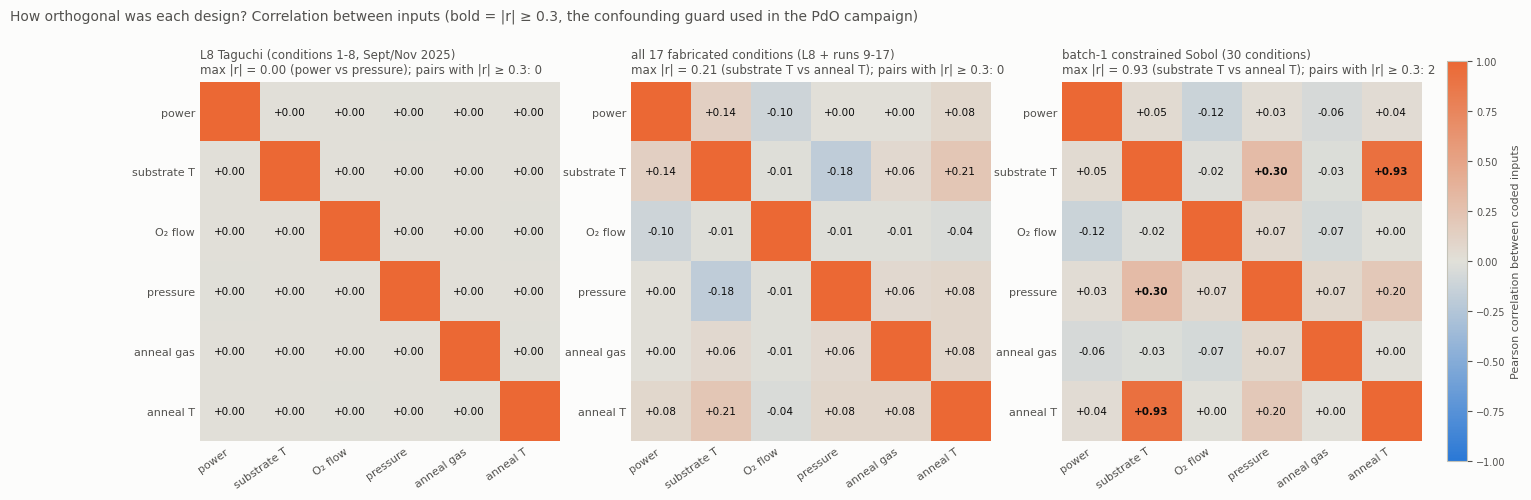

L8 Taguchi (conditions 1-8, Sept/Nov 2025): max |r| = 0.00 (power vs pressure)
all 17 fabricated conditions (L8 + runs 9-17): max |r| = 0.21 (substrate T vs anneal T)
batch-1 constrained Sobol (30 conditions): max |r| = 0.93 (substrate T vs anneal T)


In [7]:
# --- How orthogonal were the designs? Pearson correlation between the coded inputs, per design.
#     Bold = |r| >= 0.3, the confounding guard used throughout the PdO campaign.
from matplotlib.colors import LinearSegmentedColormap
cmap_div = LinearSegmentedColormap.from_list('div', [P['blue'], P['grid'], P['orange']])
SHORT = {'Power (W)': 'power', 'Substrate Temp (°C)': 'substrate T', 'O2 Flow (sccm)': 'O₂ flow', 'Pressure (mTorr)': 'pressure',
         'Anneal Condition': 'anneal gas', 'Anneal Temp (°C)': 'anneal T', 'Substrate Temperature (C)': 'substrate T',
         'Oxygen Flow Rate (sccm)': 'O₂ flow', 'Background Pressure (Torr)': 'pressure', 'Annealing Condition': 'anneal gas',
         'Annealing Temperature (C)': 'anneal T'}
def coded(df, cols):
    out = pd.DataFrame(index=df.index)
    for c in cols:
        v = df[c]
        if v.dtype == object:
            v = v.map({'O2': 1, 'N2': -1, 'O': 1, 'N': -1})
        out[SHORT[c]] = v.astype(float)
    return out
SOBOL_ORDER = ['Power (W)', 'Substrate Temperature (C)', 'Oxygen Flow Rate (sccm)', 'Background Pressure (Torr)', 'Annealing Condition', 'Annealing Temperature (C)']
designs = {'L8 Taguchi (conditions 1-8, Sept/Nov 2025)': coded(cond.loc[1:8], FAC),
           'all 17 fabricated conditions (L8 + runs 9-17)': coded(cond, FAC),
           'batch-1 constrained Sobol (30 conditions)': coded(u, SOBOL_ORDER)}
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2))
maxr = {}
for ax, (name, X) in zip(axes, designs.items()):
    r = X.corr().fillna(0.0)
    im = ax.imshow(r.to_numpy(), cmap=cmap_div, vmin=-1, vmax=1)
    for i in range(len(r)):
        for j in range(len(r)):
            if i != j:
                v = r.iloc[i, j]
                ax.text(j, i, f'{(0.0 if abs(v) < 0.005 else v):+.2f}', ha='center', va='center', fontsize=7.5, color=P['ink'], fontweight='bold' if abs(v) >= 0.3 else 'normal')
    ax.set_xticks(range(len(r))); ax.set_xticklabels(r.columns, rotation=35, ha='right', fontsize=8)
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.index, fontsize=8)
    ax.grid(False); ax.tick_params(length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
    off = r.where(~np.eye(len(r), dtype=bool)).abs()
    maxr[name] = (off.max().max(), off.stack().idxmax())
    n_bad = int((off.stack() >= 0.3).sum() // 2)
    ax.set_title(f'{name}\nmax |r| = {off.max().max():.2f} ({off.stack().idxmax()[0]} vs {off.stack().idxmax()[1]}); pairs with |r| ≥ 0.3: {n_bad}', loc='left', fontsize=8.5, color=P['ink2'])
cb = fig.colorbar(im, ax=axes.tolist(), fraction=0.025, pad=0.02); cb.set_label('Pearson correlation between coded inputs', fontsize=8); cb.ax.tick_params(labelsize=7)
fig.suptitle('How orthogonal was each design? Correlation between inputs (bold = |r| ≥ 0.3, the confounding guard used in the PdO campaign)', x=0.01, ha='left', fontsize=10, color=P['ink2'])
save('design_correlation_fig', fig); plt.show()
for name, (v, pair) in maxr.items():
    print(f'{name}: max |r| = {v:.2f} ({pair[0]} vs {pair[1]})')

**Reading the matrices.** The L8 is exactly orthogonal — every off-diagonal entry is 0.00 — which is what an orthogonal
array promises: the six main effects can be estimated without confounding among themselves (the aliasing of each main
effect with two-factor interactions is a separate matter that a correlation matrix cannot show). Adding runs 9–17 kept
the pooled design under the guard (largest |r| = 0.21, substrate vs anneal temperature), so the Taguchi-phase ANOVA above
is not distorted by correlated inputs; its limits come from the two-level structure, not from confounding. The batch-1
Sobol sheet keeps every pair at or below 0.30 except substrate vs anneal temperature at 0.93. That one is built in by the
rule "anneal above substrate" together with the 25 °C level: four cold runs with low anneals against 26 hot runs with high
anneals form two clusters, and two clusters correlate. Within the heated runs alone the two temperatures correlate at only
0.39, so they remain separable there; what batch 1 cannot do is tell a "room-temperature" effect from a "low-anneal"
effect, because in this batch they are the same four runs. §7 shows how the 435–600 °C revision changes this picture.

## 6. The batch-1 design as received: coverage, constraint, balance

Thirty points cannot fill six dimensions densely, but a Sobol batch should leave no large holes and no accidental factor
correlations. One correlation is intentional: because the anneal is drawn above the substrate temperature and the four
room-temperature runs sit at 25 °C, substrate and anneal temperature are strongly correlated by construction — that pair is
excluded when judging balance.

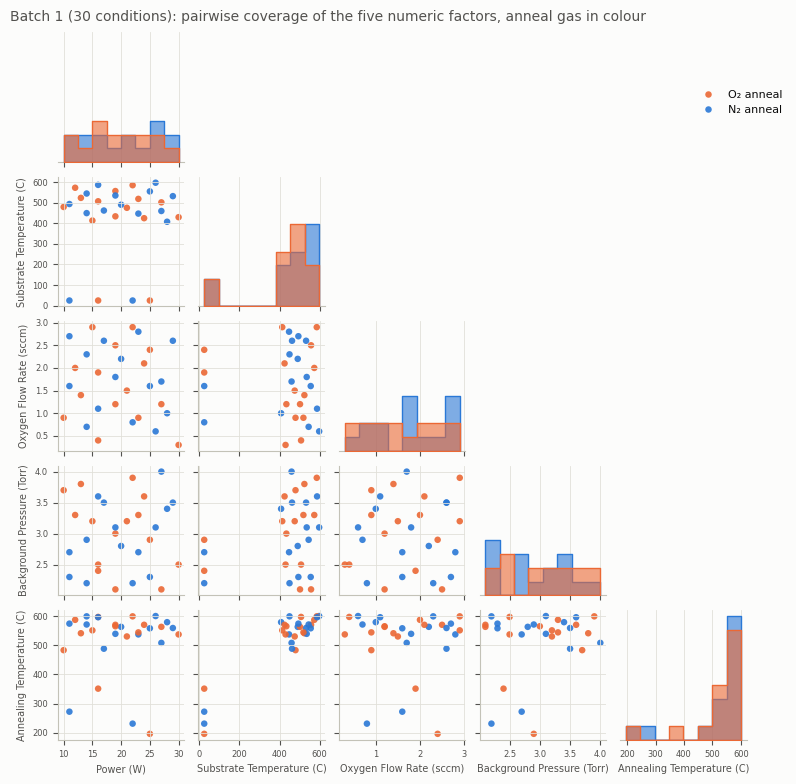

|correlation| substrate vs anneal: 0.93 (built in by the rule anneal > substrate and the 25 C level); largest |correlation| among all other factor pairs (gas as 0/1): 0.30 (Substrate Temperature (C) vs Background Pressure (Torr))


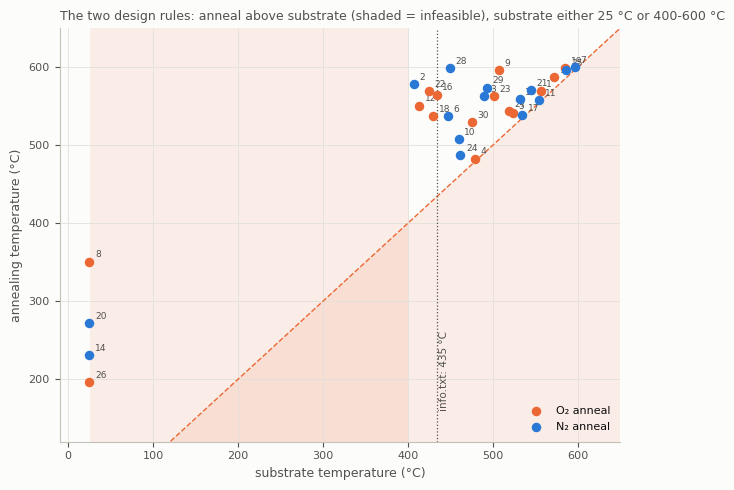

In [8]:
import seaborn as sns
d = u.reset_index().copy(); d['gas'] = d['Annealing Condition'].map({'O': 'O₂ anneal', 'N': 'N₂ anneal'})
g = sns.pairplot(d[NUM + ['gas']], hue='gas', palette={'O₂ anneal': P['orange'], 'N₂ anneal': P['blue']}, corner=True,
                 diag_kind='hist', height=1.55, plot_kws=dict(s=22, alpha=0.9, edgecolor='none'), diag_kws=dict(alpha=0.6, bins=8, element='step'))
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=6); ax.xaxis.label.set_size(7); ax.yaxis.label.set_size(7)
g.figure.suptitle('Batch 1 (30 conditions): pairwise coverage of the five numeric factors, anneal gas in colour', x=0.02, ha='left', y=1.01, fontsize=10, color=P['ink2'])
sns.move_legend(g, 'upper right', bbox_to_anchor=(0.92, 0.92), title=None, frameon=False)
save('design_pairs_fig', g.figure); plt.show()

X = d[NUM].astype(float).copy(); X['gas'] = (d['Annealing Condition'] == 'O').astype(float)
corr = X.corr(); offdiag = corr.where(~np.eye(len(corr), dtype=bool)).abs()
sub, ann = 'Substrate Temperature (C)', 'Annealing Temperature (C)'
rest = offdiag.copy(); rest.loc[sub, ann] = rest.loc[ann, sub] = np.nan
print(f'|correlation| substrate vs anneal: {offdiag.loc[sub, ann]:.2f} (built in by the rule anneal > substrate and the 25 C level); '
      f'largest |correlation| among all other factor pairs (gas as 0/1): {rest.max().max():.2f} ({rest.stack().idxmax()[0]} vs {rest.stack().idxmax()[1]})')

fig, ax = plt.subplots(figsize=(6.4, 5))
ax.fill_between([0, 650], [0, 650], 0, color=P['orange'], alpha=0.10, lw=0)
ax.axvspan(25.5, 400, color=P['orange'], alpha=0.10, lw=0)
ax.plot([0, 650], [0, 650], color=P['orange'], lw=1, ls='--')
ax.axvline(435, color=P['ink2'], lw=0.9, ls=':')
ax.text(437, 160, 'info.txt: 435 °C', fontsize=7.5, color=P['ink2'], rotation=90, va='bottom')
for gas, c in [('O', P['orange']), ('N', P['blue'])]:
    s = d[d['Annealing Condition'] == gas]
    ax.scatter(s['Substrate Temperature (C)'], s['Annealing Temperature (C)'], s=34, color=c, zorder=4, label=f'{gas}₂ anneal')
    for _, r in s.iterrows():
        ax.annotate(int(r['Sample']), (r['Substrate Temperature (C)'], r['Annealing Temperature (C)']), xytext=(4, 3), textcoords='offset points', fontsize=6.5, color=P['ink2'])
ax.set_xlim(-10, 650); ax.set_ylim(120, 650); ax.set_xlabel('substrate temperature (°C)'); ax.set_ylabel('annealing temperature (°C)')
ax.set_title('The two design rules: anneal above substrate (shaded = infeasible), substrate either 25 °C or 400-600 °C', loc='left', color=P['ink2'])
ax.legend(loc='lower right'); fig.tight_layout(); save('design_constraint_fig', fig); plt.show()

**Reading the design.** Coverage of power, O₂ flow and pressure is even and the factor pairs other than substrate–anneal
stay below |r| ≈ 0.3. The ordering rule has a side effect worth knowing: for the heated runs the anneal temperature is
squeezed into ≈ 480–600 °C, so the 150–480 °C part of the anneal range is explored only by the four room-temperature runs
(196–350 °C). If room-temperature depositions are dropped (§7), batch 1 contains no low-temperature anneal at all.

## 7. The question in `info.txt`: "integer substrate temperatures from 435 to 600 °C?"

The request changes two things: the **resolution** (integers instead of one decimal, trivially fine) and the **range**
(435–600 °C instead of 400–600 °C, which also leaves no room for the 25 °C runs). The cell below quantifies what that does to
the received sheet and prepares two ways to honour it:

- **Revision A — minimal edit.** Round the heated substrate temperatures to integers and lift the ones below 435 °C to
  435 °C; keep the four RT runs. Most of the approved design survives unchanged.
- **Revision B — regenerate.** Re-run the same generator (same seed) with the substrate range 435–600 °C and integer
  rounding, once keeping the RT level and once without it (if "435–600" means room-temperature depositions are over).

Space-filling metrics (centred L2 discrepancy, largest factor correlation, smallest normalised pairwise distance) are
computed on the **heated** conditions only (room-temperature runs are a separate level, reported as a count), with the
substrate temperature scaled to each variant's *intended* range, so every variant is judged on how well it fills the space
it is meant to fill. The substrate–anneal correlation is reported on its own because the design rule (anneal above
substrate) creates it on purpose; the other factor pairs are what should stay near zero.

In [9]:
from scipy.spatial.distance import pdist
sub, ann = 'Substrate Temperature (C)', 'Annealing Temperature (C)'
heated = u[sub] > 25
print(f'heated conditions: {int(heated.sum())}; below 435 C: {int((heated & (u[sub] < 435)).sum())} '
      f'(samples {u.index[heated & (u[sub] < 435)].tolist()}, {u.loc[heated & (u[sub] < 435), sub].min():.1f}-{u.loc[heated & (u[sub] < 435), sub].max():.1f} C); '
      f'non-integer: {int((heated & (u[sub] != u[sub].round())).sum())}; room-temperature runs outside 435-600: {int((~heated).sum())}')

# Revision A: integer + clamp to >= 435 for heated runs, RT untouched
revA = u.copy()
revA[sub] = np.where(heated, np.clip(np.round(u[sub]), 435, 600), 25).astype(int)
changes = pd.DataFrame({'received': u[sub], 'revision A': revA[sub], 'shift (C)': revA[sub] - u[sub], 'anneal (C)': u[ann]})
changes = changes[changes['shift (C)'].abs() > 0.5]
print(f'\nrevision A: {int((revA[sub] != u[sub]).sum())} of 30 substrate values change; shifts larger than rounding:'); display(changes); print(changes.to_string())
print('revision A keeps substrate < anneal for every condition:', bool((revA[sub] < revA[ann]).all()))

# Revision B: regenerate with the new substrate range (same seed), with and without the RT level
revB = generate_batch(substrate_bounds=(435.0, 600.0), integer_substrate=True).set_index('Sample')
revB_noRT = generate_batch(substrate_bounds=(435.0, 600.0), integer_substrate=True, prob_room_temp=0.0).set_index('Sample')

LO = np.array([10, 0, 0.3, 2.0, 150, 0]); HI = np.array([30, 1, 3.0, 4.0, 600, 1])     # substrate bounds set per variant
def design_metrics(df, sub_range):
    # heated conditions only (room temperature is a separate level, reported as a count); substrate scaled to the variant's intended range
    h = df[df[sub] > 25]
    X = h[NUM].astype(float).to_numpy(); X = np.column_stack([X, (h['Annealing Condition'] == 'O').astype(float)])
    lo, hi = LO.astype(float).copy(), HI.astype(float).copy(); lo[1], hi[1] = sub_range
    Uq = np.clip((X - lo) / (hi - lo), 0, 1)
    c = np.abs(np.corrcoef(Uq.T)); iu = np.triu_indices(6, 1); off = c[iu]
    excl = np.array([(i, j) != (1, 4) for i, j in zip(*iu)])              # the substrate (1) - anneal (4) pair is reported separately
    return dict(n=len(df), rt_runs=int((df[sub] == 25).sum()), heated=len(h), intended_substrate_range=f'{sub_range[0]:g}-{sub_range[1]:g}',
                observed_substrate=f'{h[sub].min():g}-{h[sub].max():g}', discrepancy_CD=float(qmc.discrepancy(Uq, method='CD')),
                corr_sub_anneal=float(c[1, 4]), max_abs_corr_other_pairs=float(off[excl].max()), min_pairwise_dist=float(pdist(Uq).min()),
                constraint_ok=bool((df[sub] < df[ann]).all()),
                unchanged_vs_received=int((df[NUM + ['Annealing Condition']].reset_index(drop=True) == u[NUM + ['Annealing Condition']].reset_index(drop=True)).all(axis=1).sum()))
metrics = pd.DataFrame({'received (400-600, 1 decimal)': design_metrics(u, (400, 600)), 'A: rounded + clamped to 435': design_metrics(revA, (435, 600)),
                        'B: regenerated 435-600, RT kept': design_metrics(revB, (435, 600)), 'B: regenerated 435-600, no RT': design_metrics(revB_noRT, (435, 600))}).T
display(metrics); print(metrics.to_string())
save('revision_metrics_table', {'metrics': metrics.rename_axis('variant').reset_index(), 'revision_A_changes': changes.rename_axis('Sample').reset_index()})
save('revision_A_sheet', repeated(revA.reset_index())); save('revision_B_sheet', repeated(revB.reset_index())); save('revision_B_noRT_sheet', repeated(revB_noRT.reset_index()))

heated conditions: 26; below 435 C: 5 (samples [2, 12, 16, 18, 22], 407.7-433.9 C); non-integer: 24; room-temperature runs outside 435-600: 4

revision A: 24 of 30 substrate values change; shifts larger than rounding:


,received,revision A,shift (C),anneal (C)
Sample,,,,
2,407.7,435,27.3,579
12,413.4,435,21.6,551
16,433.9,435,1.1,565
18,429.8,435,5.2,537
22,424.9,435,10.1,570


        received  revision A  shift (C)  anneal (C)
Sample                                             
2          407.7         435       27.3         579
12         413.4         435       21.6         551
16         433.9         435        1.1         565
18         429.8         435        5.2         537
22         424.9         435       10.1         570
revision A keeps substrate < anneal for every condition: True


,n,rt_runs,heated,intended_substrate_range,observed_substrate,discrepancy_CD,corr_sub_anneal,max_abs_corr_other_pairs,min_pairwise_dist,constraint_ok,unchanged_vs_received
"received (400-600, 1 decimal)",30,4,26,400-600,407.7-597.2,0.533847,0.388198,0.300795,0.285397,True,30
A: rounded + clamped to 435,30,4,26,435-600,435-597,0.567014,0.425827,0.300795,0.311712,True,6
"B: regenerated 435-600, RT kept",30,4,26,435-600,441-598,0.566621,0.391219,0.30091,0.280998,True,4
"B: regenerated 435-600, no RT",30,0,30,435-600,436-598,0.518309,0.658273,0.209424,0.261706,True,0


                                  n rt_runs heated intended_substrate_range observed_substrate discrepancy_CD corr_sub_anneal max_abs_corr_other_pairs min_pairwise_dist constraint_ok unchanged_vs_received
received (400-600, 1 decimal)    30       4     26                  400-600        407.7-597.2       0.533847        0.388198                 0.300795          0.285397          True                    30
A: rounded + clamped to 435      30       4     26                  435-600            435-597       0.567014        0.425827                 0.300795          0.311712          True                     6
B: regenerated 435-600, RT kept  30       4     26                  435-600            441-598       0.566621        0.391219                  0.30091          0.280998          True                     4
B: regenerated 435-600, no RT    30       0     30                  435-600            436-598       0.518309        0.658273                 0.209424          0.261706          Tr

**Correlation between inputs for each variant** — the same check as in §5, over the 30 conditions each variant would send to
the fab (the titles also give the substrate–anneal correlation among the heated runs alone).

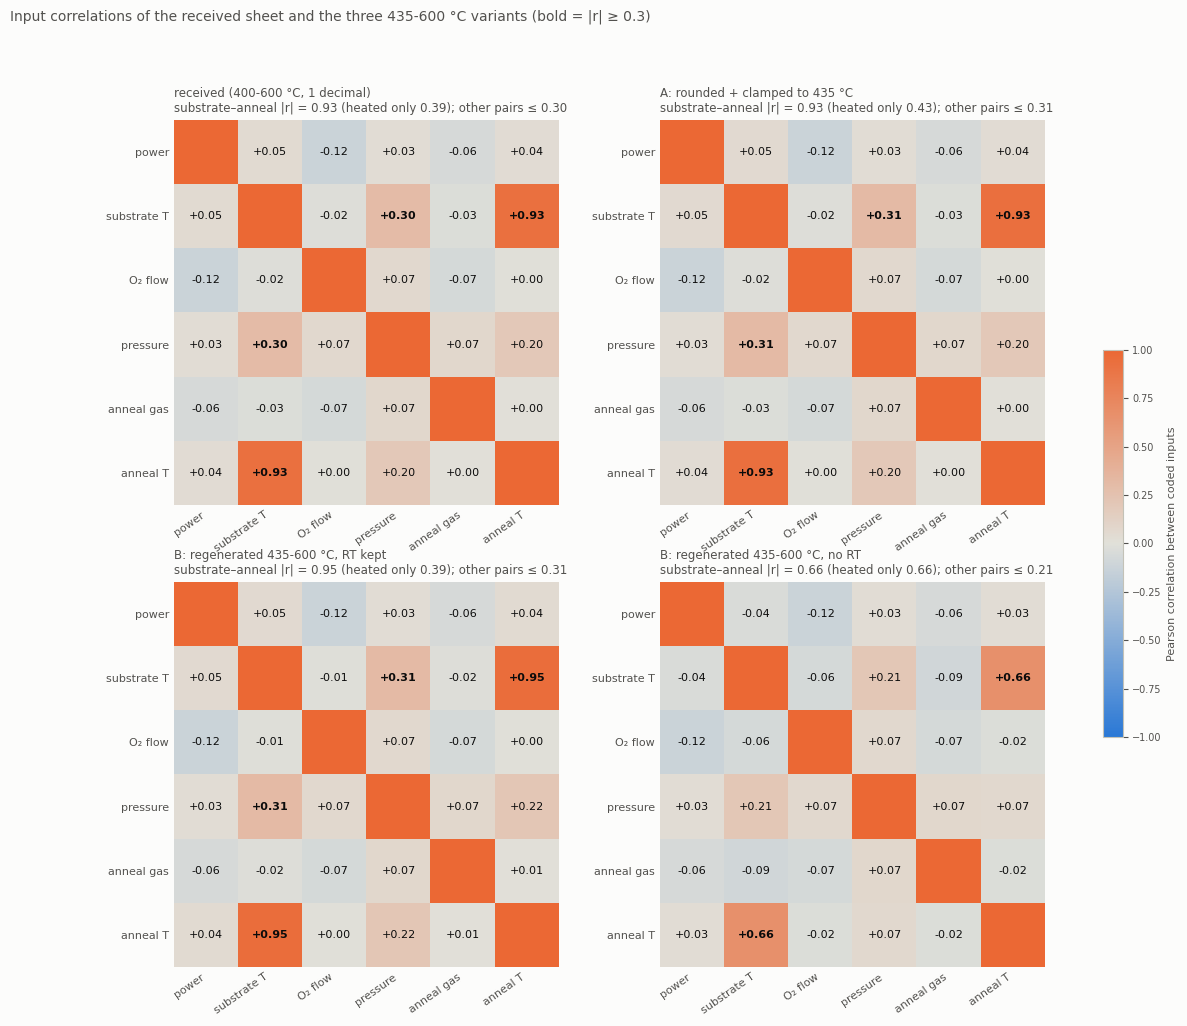

In [10]:
variants = {'received (400-600 °C, 1 decimal)': u, 'A: rounded + clamped to 435 °C': revA,
            'B: regenerated 435-600 °C, RT kept': revB, 'B: regenerated 435-600 °C, no RT': revB_noRT}
fig, axes = plt.subplots(2, 2, figsize=(12.5, 11))
for ax, (name, d) in zip(axes.ravel(), variants.items()):
    r = coded(d, SOBOL_ORDER).corr().fillna(0.0)
    im = ax.imshow(r.to_numpy(), cmap=cmap_div, vmin=-1, vmax=1)
    for i in range(len(r)):
        for j in range(len(r)):
            if i != j:
                v = r.iloc[i, j]
                ax.text(j, i, f'{(0.0 if abs(v) < 0.005 else v):+.2f}', ha='center', va='center', fontsize=8, color=P['ink'], fontweight='bold' if abs(v) >= 0.3 else 'normal')
    ax.set_xticks(range(len(r))); ax.set_xticklabels(r.columns, rotation=35, ha='right', fontsize=8)
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.index, fontsize=8); ax.grid(False); ax.tick_params(length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
    off = r.where(~np.eye(len(r), dtype=bool)).abs()
    sa = off.loc['substrate T', 'anneal T']; rest = off.copy(); rest.loc['substrate T', 'anneal T'] = rest.loc['anneal T', 'substrate T'] = np.nan
    hot = d[d[sub] > 25]; sa_hot = coded(hot, SOBOL_ORDER).corr().abs().loc['substrate T', 'anneal T']
    ax.set_title(f'{name}\nsubstrate–anneal |r| = {sa:.2f} (heated only {sa_hot:.2f}); other pairs ≤ {rest.max().max():.2f}',
                 loc='left', fontsize=8.5, color=P['ink2'])
cb = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.06, shrink=0.6); cb.set_label('Pearson correlation between coded inputs', fontsize=8); cb.ax.tick_params(labelsize=7)
fig.suptitle('Input correlations of the received sheet and the three 435-600 °C variants (bold = |r| ≥ 0.3)', x=0.01, ha='left', fontsize=10, color=P['ink2'])
save('revision_correlation_fig', fig); plt.show()

**Reading the matrices.** The revision does not change how well-conditioned the design is. Every variant that keeps the
four room-temperature runs has the same picture as the received sheet: the substrate–anneal pair at 0.93–0.95, produced by
the cold/hot two-cluster structure, and every other pair at or below 0.31 (the pairs touching 0.30 — pressure with
substrate, pressure with anneal — are inherited from the received sheet, not created by the clamp). Among the heated runs
alone the two temperatures correlate at only 0.39–0.43, so the heated part of the design can separate them. Dropping room
temperature (variant B, no RT) is the only change that alters the conditioning: the overall substrate–anneal correlation
falls to 0.66 and the largest other pair to 0.21, the best-conditioned batch of the four — at the price of having no
room-temperature and no low-anneal information at all.

**What to answer.** Rounding to integers costs nothing. The range change is the real decision:

- **Revision A** touches only the five conditions that sit between 400 and 435 °C (lifted by at most ≈ 27 °C), keeps the
  anneal-above-substrate rule intact, and leaves the other 25 conditions as the fab team already has them (apart from
  rounding). Its only cost is a small cluster at exactly 435 °C; its space-filling metrics are within a few per cent of the
  regenerated variants.
- **Revision B** restores uniform coverage of the new 435–600 °C range but is a *new* set of 30 conditions; nothing the fab
  team may already have prepared carries over.
- **The four room-temperature runs are not covered by "435–600 °C".** Whether RT depositions are dropped (then use the
  "no RT" variant, or simply fabricate the 26 heated conditions) or kept as a separate level is the fab team's call, and the
  question to send back together with the revised sheet. Two smaller things to confirm at the same time: that the pressure
  column is in mTorr (the header says Torr), and whether the 0.1 sccm / 0.1 mTorr settings in the sheet are what the tool can
  actually hold.

Set `SAVE_OUTPUTS = True` to write both revised run sheets (with the three repetitions) next to the metrics table.

**Decision (2026-10-08).** Since the fab team has no measurements yet, batch 1 is **recomputed**: integer substrate
temperatures in 435–600 °C and **no room-temperature runs** (the request named only that range). The generator was chosen in
`doe/inox/inox_batch1_sampler_comparison.ipynb`, which compares Sobol with Halton, plain and optimised Latin hypercubes and
the UIC-style LHS optimised on discrepancy + w × |r| on this space: the chosen design is the **CD + 0.1 × |r| Latin
hypercube, seed 8** (front pick of the weight sweep; closest pair 0.37, factor correlation 0.014, largest hole 0.74), with
the screened Sobol seed 48 kept as the alternative. §6 of that notebook writes the run sheet and its figures to
`output/inox/batch1_design/` when its `SAVE_*` flags are set (nothing is stored by default).

## 8. Summary

1. **What it is.** The 06_10_26 workbook is a run sheet, not data: 30 conditions × 3 repetitions of the six InOx process
   factors, identical to batch 1 (seed 42) of the constrained Sobol generator in `doe/inox/doe_design.ipynb`. The fab team is
   returning the design for confirmation with one change request on the substrate temperature.
2. **Which project.** The InOx thin-film-transistor campaign (Ta-containing sputtered indium oxide, "BEOL" process window),
   objective Hall mobility, with XPS (In 3d, O 1s, Ta 4f) and XRD (up to three peaks) as secondary outputs.
3. **What came before.** An L8 Taguchi screening (Sept 2025, 50 W films insulating), its replicated repeat at ≤ 30 W
   (Nov 2025) and an augmentation with 20 W / 2.0 sccm / 600 °C levels (Feb 2026): 17 conditions, 51 films, best
   90.7 ± 0.6 cm²/V·s at 20 W / 400 °C substrate / 2.0 sccm / O₂ 600 °C (condition 11), with the 600 °C anneals filling the
   top of the ranking; anneal temperature, power, O₂ flow and substrate temperature significant, pressure and gas not. The
   promising region (10–20 W, 400 °C substrate, 2–3 sccm, 600 °C anneal) is mapped in §4; batch 1 samples it and the
   never-visited cells around it.
4. **Why Taguchi, then Sobol.** The orthogonal array was the cheapest way to learn which knobs matter and where the safe
   ranges are; two levels cannot locate an optimum and a GP trained on the corner points does not generalise (held-out
   R² ≈ 0.2), so the campaign moved to a space-filling design over continuous ranges with the T_sub < T_anneal rule.
5. **The decision.** Integer substrate temperatures in 435–600 °C change 24 of the 26 heated conditions (5 of them by
   more than rounding) and exclude the four room-temperature runs. Because no measurements exist yet, the batch is
   recomputed from the new range with no room-temperature runs as a CD + 0.1 × |r| Latin hypercube (seed 8), chosen in
   `doe/inox/inox_batch1_sampler_comparison.ipynb`, whose §6 writes the run sheet to `output/inox/batch1_design/` on request.